# MySteth 2.0 — RQ2 (part a): self-supervised pretraining, per fold, on two corpora

**RQ2 (methods document).** *How does self-supervised representation learning affect uncertainty quality and calibration in paediatric murmur detection?* The methods document asks for an encoder pretrained with BYOL-A on **CirCor + PhysioNet 2016 (adult) + PASCAL**, flagged explicitly as a **domain-shift experiment**, "not assumed to help by default". This notebook builds the encoders; **part b** compares them.

### The five MySteth 2.0 components and their role here

| # | Component | Role in this notebook |
|---|---|---|
| ① | **SQA** | **Off.** Pretraining uses every recording, good or poor; no labels are used at all. |
| ② | **SSL** (BYOL-A encoder) | **Built here:** two pretraining corpora × three folds = six encoders. |
| ③ | **Multi-task heads** | Off (part b and RQ3). |
| ④ | **UQ** | Off (part b). |
| ⑤ | **XAI** | Off (RQ5). |

### What is new compared with the original encoder (`byola_encoder.pt`)

| | original encoder | this notebook |
|---|---|---|
| Which CirCor recordings | all 3,163, **including every future test recording** (transductive) | **per fold:** only recordings outside that fold's test set. No test recording is ever seen, even without labels. |
| Corpora | CirCor only | **CirCor-SSL:** CirCor (fold's non-test part). **Domain-SSL:** the same CirCor recordings + PhysioNet 2016 + PASCAL. |
| Budget | 300 epochs over 3,163 recordings (≈ 7,400 updates) | **7,500 updates for every encoder**, whatever its corpus size, so CirCor-SSL and Domain-SSL differ only in **which data** they learn from, not in how much training they get |
| Recipe | BYOL-A: SmallResNet encoder (512-d), projector/predictor MLPs (1024 → 256), Adam 3e-4, weight decay 1e-6, cosine learning rate, EMA momentum 0.996 → 1 (cosine), batch 128, two independently cropped and augmented 5 s views | **unchanged** |

### Files written (`/kaggle/working/rq2a_outputs`)
- `rq2_folds.csv`: **the one folds file every later RQ uses** (same code and seed as before, so the folds are identical to the first RQ2 run)
- `encoders/byola_circor_f{0,1,2}.pt` and `encoders/byola_domain_f{0,1,2}.pt`
- `rq2a_corpus_summary.csv`, `rq2a_pretraining_loss.csv`, `figures/rq2a_loss.png`

### Kaggle setup
- **GPU on.** Internet is only needed if PhysioNet 2016 is not attached (the notebook then downloads it from physionet.org).
- Attach **CirCor v2**, **PASCAL** (Kaggle: "Heartbeat Sounds", folders `set_a` / `set_b`) and **PhysioNet Challenge 2016** (folders `training-a` … `training-f`). Set `pascal_root` and `pn2016_dir` below.
- **12-hour limit:** the run stops itself cleanly after about 10.75 h, keeping all checkpoints. If the last log line says *NOT FINISHED*, attach this version's output, set `resume_from` to it and run again.
- **Resuming:** every encoder saves a checkpoint every 500 updates. If a session ends, save the version, attach its output, set `resume_from`, and run again: it continues where it stopped.

In [1]:
import os, math, random, json, time, glob, shutil, zipfile, urllib.request, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Device:", device)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
NAVY, TEAL, ORANGE, GRAY = "#1F3864", "#1F8A70", "#E67E22", "#6B7280"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


@dataclass
class Config:
    # ---- EDIT THESE PATHS to match your Kaggle inputs ----
    circor_root: str = "/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2"
    pascal_root: str = "/kaggle/input/datasets/kinguistics/heartbeat-sounds"          # folder containing set_a / set_b (searched recursively for .wav)
    pn2016_urls: tuple = ("https://physionet.org/files/challenge-2016/1.0.0/training.zip",
                          "https://archive.physionet.org/pn3/challenge/2016/training.zip")
    pn2016_dir: str = "/kaggle/input/datasets/bjoernjostein/physionet-challenge-2016"                              # download / unzip location (not kept in the output)
    output_dir: str = "/kaggle/working/rq2a_outputs"
    resume_from: str = "/kaggle/input/notebooks/tusharrbb/rq2-part-1-again/rq2a_outputs"                                         # e.g. "/kaggle/input/rq2a-partial/rq2a_outputs"

    # audio / spectrogram (identical to every other notebook)
    sample_rate: int = 4000
    n_fft: int = 256
    hop_length: int = 32
    n_mels: int = 64
    fmin: float = 20.0
    fmax: float = 800.0
    window_sec: float = 5.0

    # BYOL-A (original recipe)
    embed_dim: int = 512
    hidden_dim: int = 1024
    proj_dim: int = 256
    ema_momentum: float = 0.996
    batch_size: int = 128
    lr: float = 3e-4
    weight_decay: float = 1e-6
    total_steps: int = 7500          # same number of updates for every encoder
    ckpt_every: int = 500

    # folds (identical to the first RQ2 run)
    n_folds: int = 3
    cal_frac: float = 0.15
    val_frac: float = 0.10

cfg = Config()
T_START = time.time()
TIME_BUDGET_H = 10.75          # stop cleanly before Kaggle's 12 h limit; resume in a new run
cfg.data_dir = os.path.join(cfg.circor_root, "training_data", "training_data")
OUT = Path(cfg.output_dir); OUT.mkdir(parents=True, exist_ok=True)
ENC_DIR = OUT / "encoders"; ENC_DIR.mkdir(exist_ok=True)
CKPT_DIR = OUT / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)
CORPORA = ["circor", "domain"]
print(cfg)

Device: cuda
Config(circor_root='/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2', pascal_root='/kaggle/input/datasets/kinguistics/heartbeat-sounds', pn2016_urls=('https://physionet.org/files/challenge-2016/1.0.0/training.zip', 'https://archive.physionet.org/pn3/challenge/2016/training.zip'), pn2016_dir='/kaggle/input/datasets/bjoernjostein/physionet-challenge-2016', output_dir='/kaggle/working/rq2a_outputs', resume_from='/kaggle/input/notebooks/tusharrbb/rq2-part-1-again/rq2a_outputs', sample_rate=4000, n_fft=256, hop_length=32, n_mels=64, fmin=20.0, fmax=800.0, window_sec=5.0, embed_dim=512, hidden_dim=1024, proj_dim=256, ema_momentum=0.996, batch_size=128, lr=0.0003, weight_decay=1e-06, total_steps=7500, ckpt_every=500, n_folds=3, cal_frac=0.15, val_frac=0.1)


## 1. CirCor recordings, patient groups and the shared folds file

*Components: none yet (bookkeeping).*

This is the same code, seed and rules as the first RQ2 run, so the folds are **identical** to it:
- **Groups:** repeat-visit children (linked by `Additional ID`) form one group.
- **Folds:** 3 folds split by group, balanced on murmur × outcome.
- **Roles inside each fold:** `train` 75 % / `val` 10 % / `cal` 15 %, by group.

Pretraining for fold *f* uses every CirCor recording whose fold is **not** *f*. No labels are used, and the test recordings of fold *f* are never seen.

In [2]:
meta_path = next(iter(sorted(glob.glob(os.path.join(cfg.circor_root, "**", "training_data.csv"), recursive=True))), None)
assert meta_path, "training_data.csv (CirCor patient metadata) not found under circor_root"
meta = pd.read_csv(meta_path)
print("metadata file:", meta_path, "| columns:", list(meta.columns))
if "Outcome" not in meta.columns:
    # fall back to the per-patient .txt headers, which always carry '#Outcome: Normal/Abnormal'
    out_map = {}
    for txt in Path(cfg.data_dir).glob("*.txt"):
        for line in open(txt):
            if line.startswith("#Outcome:"):
                out_map[int(txt.stem)] = line.split(":", 1)[1].strip()
                break
    meta["Outcome"] = meta["Patient ID"].astype(int).map(out_map)
    print(f"Outcome read from .txt files: {meta.Outcome.notna().sum()} of {len(meta)} patients")
assert meta["Outcome"].isin(["Normal", "Abnormal"]).all(), "some patients have no outcome label"

wavs = sorted(Path(cfg.data_dir).glob("*.wav"))
man = pd.DataFrame({"wav_path": [str(p) for p in wavs], "wid": [p.stem for p in wavs]})
man["patient_id"] = man.wid.str.split("_").str[0].astype(int)
man["location"] = man.wid.str.split("_").str[1]
man = man.merge(meta[["Patient ID", "Murmur", "Outcome"]].rename(
    columns={"Patient ID": "patient_id", "Murmur": "murmur", "Outcome": "outcome"}), on="patient_id", how="inner")

parent = {}
def find(a):
    parent.setdefault(a, a)
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for pid, add in zip(meta["Patient ID"], meta["Additional ID"]):
    find(int(pid))
    if pd.notna(add):
        parent[find(int(pid))] = find(int(add))
man["group"] = man.patient_id.map(find)

man = man.sort_values("wid").reset_index(drop=True)
man["y_murmur"] = man.murmur.map({"Present": 1, "Absent": 0}).fillna(-1).astype(int)   # Unknown = -1
man["y_outcome"] = man.outcome.map({"Abnormal": 1, "Normal": 0}).astype(int)
man["stratum"] = man.murmur + "|" + man.outcome

sgkf = StratifiedGroupKFold(n_splits=cfg.n_folds, shuffle=True, random_state=SEED)
man["fold"] = -1
for f, (_, te) in enumerate(sgkf.split(man, man.stratum, groups=man.group)):
    man.loc[te, "fold"] = f
assert man.groupby("group").fold.nunique().max() == 1

grp = man.sort_values("patient_id").drop_duplicates("group")[["group", "stratum", "fold"]]
for f in range(cfg.n_folds):
    tr_groups = grp[grp.fold != f]
    rest, cal = train_test_split(tr_groups, test_size=cfg.cal_frac, stratify=tr_groups.stratum, random_state=SEED + f)
    tr, val = train_test_split(rest, test_size=cfg.val_frac / (1 - cfg.cal_frac), stratify=rest.stratum, random_state=SEED + f)
    role = np.where(man.fold.values == f, "test", "train").astype(object)
    role[man.group.isin(cal.group).values] = "cal"
    role[man.group.isin(val.group).values] = "val"
    man[f"role_f{f}"] = role

FOLD_COLS = ["wid", "patient_id", "group", "location", "murmur", "outcome", "y_murmur", "y_outcome", "fold"] + [f"role_f{f}" for f in range(cfg.n_folds)]
man[FOLD_COLS].to_csv(OUT / "rq2_folds.csv", index=False)
print(f"recordings {len(man)} | patients {man.patient_id.nunique()} | groups {man.group.nunique()} | saved rq2_folds.csv")
print(man.groupby("fold").agg(recordings=("wid", "size"), patients=("patient_id", "nunique")))

metadata file: /kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2/training_data.csv | columns: ['Patient ID', 'Locations', 'Age', 'Sex', 'Height', 'Weight', 'Pregnancy status', 'Murmur', 'Murmur locations', 'Most audible location', 'Systolic murmur timing', 'Systolic murmur shape', 'Systolic murmur grading', 'Systolic murmur pitch', 'Systolic murmur quality', 'Diastolic murmur timing', 'Diastolic murmur shape', 'Diastolic murmur grading', 'Diastolic murmur pitch', 'Diastolic murmur quality', 'Campaign', 'Additional ID']
Outcome read from .txt files: 942 of 942 patients
recordings 3163 | patients 942 | groups 872 | saved rq2_folds.csv
      recordings  patients
fold                      
0           1065       315
1           1061       313
2           1037       314


## 2. External corpora: PhysioNet 2016 and PASCAL

*Components: ② SSL (the extra pretraining data of the Domain-SSL encoder).*

- **PhysioNet/CinC 2016** training set, folders `training-a` … `training-f`: mostly **adult** recordings at 2 kHz. Its `validation` folder is a copy of 300 training records and is **excluded** to avoid duplicates.
- **PASCAL** heart-sound challenge (`set_a`: iStethoscope app, `set_b`: DigiScope).

Every file is resampled to 4 kHz and treated exactly like a CirCor recording. A 2 kHz recording still covers our 20–800 Hz mel range.

**No labels from these datasets are used.** They are never used for evaluation, so they can be included in every fold.

In [3]:
pn_dir = Path(cfg.pn2016_dir); pn_dir.mkdir(parents=True, exist_ok=True)
if not list(pn_dir.rglob("*.wav")):
    zpath = pn_dir / "training.zip"
    for url in cfg.pn2016_urls:
        try:
            print("downloading", url)
            urllib.request.urlretrieve(url, zpath)
            with zipfile.ZipFile(zpath) as z:
                z.extractall(pn_dir)
            break
        except Exception as e:
            print("  failed:", e)
    assert list(pn_dir.rglob("*.wav")), "PhysioNet 2016 download failed: check that Internet is on, or attach it as a dataset and set pn2016_dir"
pn_files = sorted(p for p in pn_dir.rglob("*.wav")
                  if not any(part.lower() in ("validation", "annotations") for part in p.parts))
pascal_files = sorted(Path(cfg.pascal_root).rglob("*.wav"))
assert pascal_files, f"no PASCAL .wav files under {cfg.pascal_root}: set cfg.pascal_root"
print(f"PhysioNet 2016: {len(pn_files)} recordings | PASCAL: {len(pascal_files)} recordings")

PhysioNet 2016: 3240 recordings | PASCAL: 832 recordings


## 3. Load all audio at 4 kHz; corpus summary

*Components: ② SSL (input data).*

Files that cannot be decoded, or that are shorter than 1 s, are skipped and counted; nothing else is filtered. Recording loudness is reported per corpus. No loudness normalisation is applied in any notebook, so the encoders see audio exactly as part b and the system will. The ±6 dB gain augmentation covers part of the level differences between devices.

In [4]:
def load_audio(path):
    wav, sr = torchaudio.load(str(path))
    wav = wav.mean(0) if wav.shape[0] > 1 else wav[0]
    if sr != cfg.sample_rate:
        wav = torchaudio.functional.resample(wav, sr, cfg.sample_rate)
    return wav.numpy().astype(np.float32)

def load_many(paths, name):
    out, skipped = [], 0
    for p in tqdm(paths, desc=f"loading {name}"):
        try:
            a = load_audio(p)
        except Exception:
            skipped += 1; continue
        if len(a) < cfg.sample_rate:
            skipped += 1; continue
        out.append(a)
    return out, skipped

AUDIO_C, sk_c = load_many(man.wav_path, "CirCor")
assert sk_c == 0 and len(AUDIO_C) == len(man), "every CirCor recording must load (indices must match the folds file)"
AUDIO_PN, sk_pn = load_many(pn_files, "PhysioNet 2016")
AUDIO_PA, sk_pa = load_many(pascal_files, "PASCAL")
AUDIO_EXT = AUDIO_PN + AUDIO_PA

def describe(name, aud, skipped):
    d = np.array([len(a) for a in aud]) / cfg.sample_rate
    rms = np.array([20 * np.log10(np.sqrt(np.mean(a ** 2)) + 1e-12) for a in aud])
    return {"corpus": name, "recordings": len(aud), "skipped": skipped, "hours": d.sum() / 3600,
            "median_s": np.median(d), "median_rms_dbfs": np.median(rms)}
summary = pd.DataFrame([describe("CirCor (all)", AUDIO_C, sk_c), describe("PhysioNet 2016", AUDIO_PN, sk_pn),
                        describe("PASCAL", AUDIO_PA, sk_pa)])
rows = []
for f in range(cfg.n_folds):
    n_c = int((man.fold != f).sum())
    rows.append({"fold": f, "circor_ssl_recordings": n_c, "domain_ssl_recordings": n_c + len(AUDIO_EXT),
                 "circor_epochs_at_budget": cfg.total_steps * cfg.batch_size / n_c,
                 "domain_epochs_at_budget": cfg.total_steps * cfg.batch_size / (n_c + len(AUDIO_EXT))})
per_fold = pd.DataFrame(rows)
display(summary.round(2)); display(per_fold.round(1))
summary.to_csv(OUT / "rq2a_corpus_summary.csv", index=False)
per_fold.to_csv(OUT / "rq2a_corpus_per_fold.csv", index=False)

loading CirCor:   0%|          | 0/3163 [00:00<?, ?it/s]

loading PhysioNet 2016:   0%|          | 0/3240 [00:00<?, ?it/s]

loading PASCAL:   0%|          | 0/832 [00:00<?, ?it/s]

,corpus,recordings,skipped,hours,median_s,median_rms_dbfs
0,CirCor (all),3163,0,20.09,21.46,-28.330000
1,PhysioNet 2016,3240,0,20.22,20.83,-21.120001
2,PASCAL,828,4,1.59,6.58,-22.450001


,fold,circor_ssl_recordings,domain_ssl_recordings,circor_epochs_at_budget,domain_epochs_at_budget
0,0,2098,6166,457.6,155.7
1,1,2102,6170,456.7,155.6
2,2,2126,6194,451.6,155.0


## 4. BYOL-A: two augmented views, encoder, projector, predictor, EMA target

*Components: ② SSL.*

Each training example is **two independent random 5 s crops** of one recording, each augmented separately. The augmentations are the same PCG set used everywhere else: gain, additive noise, soft-clipping, circular shift, then time and frequency masking. The online network learns to predict the target network's projection of the other view. The target is an exponential moving average of the online network. Only the **online encoder** is kept.

This is the same model and loss as the original BYOL-A notebook. Augmentation now runs in GPU batches with an independent random draw per example, which is faster and has the same distribution.

In [5]:
WIN = int(cfg.window_sec * cfg.sample_rate)
mel_tf = T.MelSpectrogram(sample_rate=cfg.sample_rate, n_fft=cfg.n_fft, hop_length=cfg.hop_length,
                          n_mels=cfg.n_mels, f_min=cfg.fmin, f_max=cfg.fmax, power=2.0).to(device)
db_tf = T.AmplitudeToDB(stype="power").to(device)
time_mask = T.TimeMasking(time_mask_param=15, iid_masks=True)
freq_mask = T.FrequencyMasking(freq_mask_param=8, iid_masks=True)

def random_crop(a):
    if len(a) > WIN:
        s = random.randint(0, len(a) - WIN); return a[s:s + WIN]
    return np.pad(a, (0, WIN - len(a)))

def augment_wave(x):
    B = x.shape[0]
    U = lambda lo, hi: torch.empty(B, device=x.device).uniform_(lo, hi)
    on = lambda p: torch.rand(B, device=x.device) < p
    gain = torch.where(on(0.8), 10 ** (U(-6, 6) / 20), torch.ones(B, device=x.device))
    x = x * gain[:, None]
    p_sig = x.pow(2).mean(1).clamp(min=1e-8)
    noise = torch.randn_like(x) * (p_sig / 10 ** (U(10, 30) / 10)).sqrt()[:, None]
    x = torch.where(on(0.5)[:, None], x + noise, x)
    drive = U(1.2, 2.0)[:, None]
    x = torch.where(on(0.3)[:, None], torch.tanh(x * drive) / torch.tanh(drive), x)
    shift = torch.randint(0, WIN, (B,), device=x.device)
    idx = (torch.arange(WIN, device=x.device)[None, :] - shift[:, None]) % WIN
    x = torch.where(on(0.5)[:, None], torch.gather(x, 1, idx), x)
    return x

def make_views(audio_list):
    x = torch.from_numpy(np.stack([random_crop(a) for a in audio_list])).to(device)
    return freq_mask(time_mask(db_tf(mel_tf(augment_wave(x))).unsqueeze(1)))


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class SmallResNetEncoder(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(32),
                                  nn.ReLU(inplace=True), nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = nn.Sequential(ResBlock(32, 64), ResBlock(64, 64))
        self.layer2 = nn.Sequential(ResBlock(64, 128, stride=2), ResBlock(128, 128))
        self.layer3 = nn.Sequential(ResBlock(128, 256, stride=2), ResBlock(256, 256))
        self.layer4 = nn.Sequential(ResBlock(256, embed_dim, stride=2), ResBlock(embed_dim, embed_dim))
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.pool(x).flatten(1)


class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.BatchNorm1d(hidden_dim),
                                 nn.ReLU(inplace=True), nn.Linear(hidden_dim, out_dim))

    def forward(self, x):
        return self.net(x)


class BYOLA(nn.Module):
    def __init__(self):
        super().__init__()
        self.online_encoder = SmallResNetEncoder(cfg.embed_dim)
        self.online_projector = MLP(cfg.embed_dim, cfg.hidden_dim, cfg.proj_dim)
        self.online_predictor = MLP(cfg.proj_dim, cfg.hidden_dim, cfg.proj_dim)
        self.target_encoder = SmallResNetEncoder(cfg.embed_dim)
        self.target_projector = MLP(cfg.embed_dim, cfg.hidden_dim, cfg.proj_dim)
        self.target_encoder.load_state_dict(self.online_encoder.state_dict())
        self.target_projector.load_state_dict(self.online_projector.state_dict())
        for p in list(self.target_encoder.parameters()) + list(self.target_projector.parameters()):
            p.requires_grad = False

    @torch.no_grad()
    def update_target(self, m):
        for o, t in zip(self.online_encoder.parameters(), self.target_encoder.parameters()):
            t.data = m * t.data + (1 - m) * o.data
        for o, t in zip(self.online_projector.parameters(), self.target_projector.parameters()):
            t.data = m * t.data + (1 - m) * o.data

    def forward(self, v1, v2):
        z1 = self.online_predictor(self.online_projector(self.online_encoder(v1)))
        z2 = self.online_predictor(self.online_projector(self.online_encoder(v2)))
        with torch.no_grad():
            t1 = self.target_projector(self.target_encoder(v1))
            t2 = self.target_projector(self.target_encoder(v2))
        return z1, z2, t1, t2

def byol_loss(z, t):
    return 2 - 2 * (F.normalize(z, dim=-1) * F.normalize(t, dim=-1)).sum(-1)

def momentum_at(step):
    return 1 - (1 - cfg.ema_momentum) * (math.cos(math.pi * step / cfg.total_steps) + 1) / 2

## 5. Pretrain six encoders (resumable)

*Components: ② SSL.*

For each fold *f* and corpus:
- **CirCor-SSL:** CirCor recordings outside fold *f*'s test set.
- **Domain-SSL:** the same recordings plus all PhysioNet 2016 and PASCAL recordings.

Both get exactly **7,500 updates** of batch 128, with recordings drawn by reshuffling the corpus each pass. The learning rate follows a cosine curve over the 7,500 updates, and EMA momentum rises from 0.996 to 1 along a cosine.

A checkpoint (online and target networks, optimiser, scheduler, step, random-number state) is written every 500 updates, so an interrupted run resumes mid-way. The finished encoder goes to `encoders/byola_<corpus>_f<fold>.pt`, and the training loss is logged every 50 updates.

In [6]:
if cfg.resume_from:
    src = Path(cfg.resume_from)
    for sub in ["encoders", "checkpoints"]:
        for fpath in (src / sub).glob("*"):
            if not (OUT / sub / fpath.name).exists():
                shutil.copy(fpath, OUT / sub / fpath.name)
    if (src / "rq2a_pretraining_loss.csv").exists() and not (OUT / "rq2a_pretraining_loss.csv").exists():
        shutil.copy(src / "rq2a_pretraining_loss.csv", OUT / "rq2a_pretraining_loss.csv")
    print("resumed from", src, "| encoders present:", sorted(p.name for p in ENC_DIR.glob("*.pt")))

loss_path = OUT / "rq2a_pretraining_loss.csv"
loss_log = pd.read_csv(loss_path).to_dict("records") if loss_path.exists() else []

def pretrain(corpus, fold):
    name = f"byola_{corpus}_f{fold}"
    final = ENC_DIR / f"{name}.pt"
    if final.exists():
        print(name, "already done"); return True
    pool = [AUDIO_C[i] for i in np.where(man.fold.values != fold)[0]]
    if corpus == "domain":
        pool = pool + AUDIO_EXT
    set_seed(SEED + 100 * fold + (0 if corpus == "circor" else 1))
    model = BYOLA().to(device)
    params = list(model.online_encoder.parameters()) + list(model.online_projector.parameters()) + list(model.online_predictor.parameters())
    opt = torch.optim.Adam(params, lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.total_steps)
    step, order, pos = 0, np.random.permutation(len(pool)), 0
    ckpt = CKPT_DIR / f"{name}.ckpt"
    if ckpt.exists():
        st = torch.load(ckpt, map_location=device, weights_only=False)
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"])
        step, order, pos = st["step"], st["order"], st["pos"]
        # random.setstate(st["py_rng"]); np.random.set_state(st["np_rng"]); torch.set_rng_state(st["torch_rng"])
        # if torch.cuda.is_available():
        #     torch.cuda.set_rng_state_all(st["cuda_rng"])
        random.setstate(st["py_rng"]); np.random.set_state(st["np_rng"]); torch.set_rng_state(st["torch_rng"].cpu())
        if torch.cuda.is_available() and st["cuda_rng"] is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in st["cuda_rng"]])
        print(f"{name}: resuming at update {step}")
    print(f"{name}: {len(pool)} recordings, {cfg.total_steps} updates (≈ {cfg.total_steps * cfg.batch_size / len(pool):.0f} passes)")
    pbar = tqdm(total=cfg.total_steps, initial=step, desc=name)
    run_loss = []
    while step < cfg.total_steps:
        if pos + cfg.batch_size > len(order):
            order, pos = np.random.permutation(len(pool)), 0
        batch = [pool[i] for i in order[pos:pos + cfg.batch_size]]; pos += cfg.batch_size
        model.train()
        z1, z2, t1, t2 = model(make_views(batch), make_views(batch))
        loss = (byol_loss(z1, t2) + byol_loss(z2, t1)).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        model.update_target(momentum_at(step))
        step += 1; run_loss.append(loss.item()); pbar.update(1)
        if step % 50 == 0:
            loss_log.append({"encoder": name, "corpus": corpus, "fold": fold, "step": step, "loss": float(np.mean(run_loss))})
            pbar.set_postfix(loss=f"{np.mean(run_loss):.4f}")
            if step % 500 == 0:
                print(f"  {name}: update {step}/{cfg.total_steps}, loss {np.mean(run_loss):.4f}, "
                      f"{(time.time() - T_START) / 3600:.2f} h elapsed", flush=True)
            run_loss = []
        if step % cfg.ckpt_every == 0 or step == cfg.total_steps:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "step": step,
                        "order": order, "pos": pos, "py_rng": random.getstate(), "np_rng": np.random.get_state(),
                        "torch_rng": torch.get_rng_state(),
                        "cuda_rng": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}, ckpt)
            pd.DataFrame(loss_log).to_csv(loss_path, index=False)
            if step < cfg.total_steps and time.time() - T_START > TIME_BUDGET_H * 3600:
                pbar.close()
                print(f"{name}: time budget reached at update {step}; checkpoint saved", flush=True)
                return False
    pbar.close()
    torch.save({k: v.cpu() for k, v in model.online_encoder.state_dict().items()}, final)
    ckpt.unlink()                                   # the finished encoder is all that is needed
    print("saved", final)
    del model, opt; torch.cuda.empty_cache()
    return True

ALL_DONE = True
for fold in range(cfg.n_folds):
    for corpus in CORPORA:
        if ALL_DONE and time.time() - T_START < TIME_BUDGET_H * 3600:
            ALL_DONE = pretrain(corpus, fold)
        else:
            ALL_DONE = False
print("encoders:", sorted(p.name for p in ENC_DIR.glob("*.pt")))
print("ALL SIX ENCODERS DONE" if ALL_DONE else
      ">>> NOT FINISHED: save this version, attach its output, set cfg.resume_from to it, run again")

resumed from /kaggle/input/notebooks/tusharrbb/rq2-part-1-again/rq2a_outputs | encoders present: ['byola_circor_f0.pt', 'byola_circor_f1.pt', 'byola_domain_f0.pt']
byola_circor_f0 already done
byola_domain_f0 already done
byola_circor_f1 already done
byola_domain_f1: resuming at update 6000
byola_domain_f1: 6170 recordings, 7500 updates (≈ 156 passes)


byola_domain_f1:  80%|########  | 6000/7500 [00:00<?, ?it/s]

  byola_domain_f1: update 6500/7500, loss 0.1069, 0.47 h elapsed
  byola_domain_f1: update 7000/7500, loss 0.1081, 0.66 h elapsed
  byola_domain_f1: update 7500/7500, loss 0.1082, 0.85 h elapsed
saved /kaggle/working/rq2a_outputs/encoders/byola_domain_f1.pt
byola_circor_f2: 2126 recordings, 7500 updates (≈ 452 passes)


byola_circor_f2:   0%|          | 0/7500 [00:00<?, ?it/s]

  byola_circor_f2: update 500/7500, loss 0.5585, 1.03 h elapsed
  byola_circor_f2: update 1000/7500, loss 0.3447, 1.22 h elapsed
  byola_circor_f2: update 1500/7500, loss 0.2738, 1.41 h elapsed
  byola_circor_f2: update 2000/7500, loss 0.2549, 1.60 h elapsed
  byola_circor_f2: update 2500/7500, loss 0.2419, 1.78 h elapsed
  byola_circor_f2: update 3000/7500, loss 0.2366, 1.97 h elapsed
  byola_circor_f2: update 3500/7500, loss 0.2247, 2.16 h elapsed
  byola_circor_f2: update 4000/7500, loss 0.2130, 2.35 h elapsed
  byola_circor_f2: update 4500/7500, loss 0.2068, 2.53 h elapsed
  byola_circor_f2: update 5000/7500, loss 0.1975, 2.72 h elapsed
  byola_circor_f2: update 5500/7500, loss 0.1918, 2.91 h elapsed
  byola_circor_f2: update 6000/7500, loss 0.1873, 3.10 h elapsed
  byola_circor_f2: update 6500/7500, loss 0.1817, 3.29 h elapsed
  byola_circor_f2: update 7000/7500, loss 0.1815, 3.47 h elapsed
  byola_circor_f2: update 7500/7500, loss 0.1812, 3.66 h elapsed
saved /kaggle/working/rq2a

byola_domain_f2:   0%|          | 0/7500 [00:00<?, ?it/s]

  byola_domain_f2: update 500/7500, loss 0.3352, 3.85 h elapsed
  byola_domain_f2: update 1000/7500, loss 0.1836, 4.04 h elapsed
  byola_domain_f2: update 1500/7500, loss 0.1481, 4.22 h elapsed
  byola_domain_f2: update 2000/7500, loss 0.1334, 4.41 h elapsed
  byola_domain_f2: update 2500/7500, loss 0.1329, 4.60 h elapsed
  byola_domain_f2: update 3000/7500, loss 0.1296, 4.79 h elapsed
  byola_domain_f2: update 3500/7500, loss 0.1360, 4.97 h elapsed
  byola_domain_f2: update 4000/7500, loss 0.1312, 5.16 h elapsed
  byola_domain_f2: update 4500/7500, loss 0.1276, 5.35 h elapsed
  byola_domain_f2: update 5000/7500, loss 0.1234, 5.54 h elapsed
  byola_domain_f2: update 5500/7500, loss 0.1240, 5.72 h elapsed
  byola_domain_f2: update 6000/7500, loss 0.1239, 5.91 h elapsed
  byola_domain_f2: update 6500/7500, loss 0.1194, 6.10 h elapsed
  byola_domain_f2: update 7000/7500, loss 0.1187, 6.29 h elapsed
  byola_domain_f2: update 7500/7500, loss 0.1215, 6.47 h elapsed
saved /kaggle/working/rq2a

## 6. Pretraining loss curves

*Components: ② SSL. A sanity check that all six encoders trained smoothly.*

The two corpora are not expected to reach the same loss value, because the views come from different recordings. What matters is that each curve falls and settles without collapsing to zero. A loss near 0 from the start would mean BYOL had collapsed, mapping everything to one point.

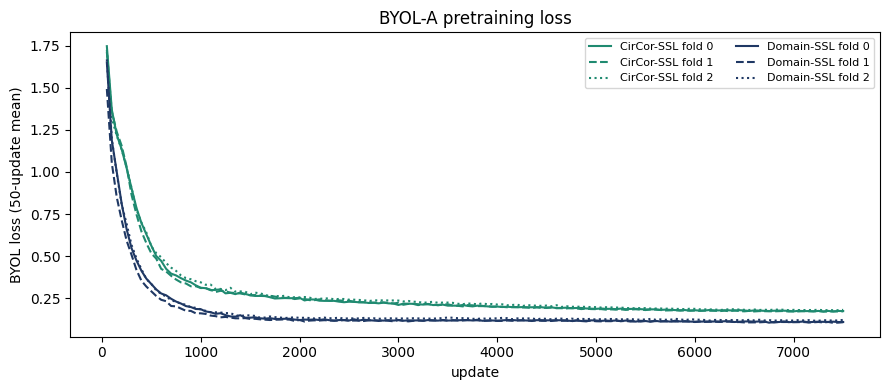

                  first    last
encoder                        
byola_circor_f0  1.7463  0.1743
byola_circor_f1  1.7122  0.1726
byola_circor_f2  1.7247  0.1812
byola_domain_f0  1.6499  0.1094
byola_domain_f1  1.4922  0.1082
byola_domain_f2  1.6683  0.1215


In [7]:
ll = pd.DataFrame(loss_log)
fig, ax = plt.subplots(figsize=(9, 4))
for (corpus, fold), g in ll.groupby(["corpus", "fold"]):
    ax.plot(g.step, g.loss, color=TEAL if corpus == "circor" else NAVY, ls=["-", "--", ":"][fold],
            label=f"{'CirCor-SSL' if corpus == 'circor' else 'Domain-SSL'} fold {fold}")
ax.set(xlabel="update", ylabel="BYOL loss (50-update mean)", title="BYOL-A pretraining loss"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "rq2a_loss.png", dpi=200); plt.show()
print(ll.groupby("encoder").loss.agg(first="first", last="last").round(4))

## 7. Hand-off to part b

Save this version, then attach its output (`rq2a_outputs`) to **RQ2 part b**. Part b needs `rq2_folds.csv` and the six files in `encoders/`.

In [8]:
if ALL_DONE:
    shutil.rmtree(CKPT_DIR, ignore_errors=True)
total = sum(f.stat().st_size for f in OUT.rglob("*") if f.is_file()) / 1e6
print(f"{OUT} ({total:.0f} MB)")
for fpath in sorted(OUT.rglob("*")):
    if fpath.is_file():
        print("  ", fpath.relative_to(OUT))

/kaggle/working/rq2a_outputs (268 MB)
   encoders/byola_circor_f0.pt
   encoders/byola_circor_f1.pt
   encoders/byola_circor_f2.pt
   encoders/byola_domain_f0.pt
   encoders/byola_domain_f1.pt
   encoders/byola_domain_f2.pt
   figures/rq2a_loss.png
   rq2_folds.csv
   rq2a_corpus_per_fold.csv
   rq2a_corpus_summary.csv
   rq2a_pretraining_loss.csv
